In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import numpy as np
import keras
from keras import Model
from keras.layers import Activation, BatchNormalization, Conv2D, Conv2DTranspose, MaxPooling2D, Dropout, Input, Rescaling

import cv2
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [21, 9]

# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(1234)

In [2]:
inputs = Input(shape=(67, 160, 3))
net = Conv2DTranspose(32, 3, strides=2, padding='same')(inputs)
net = BatchNormalization()(net)
net = Activation("relu")(net)
net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
net = BatchNormalization()(net)
net = Activation("relu")(net)
net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
net = BatchNormalization()(net)
net = Activation("relu")(net)
outputs = Conv2D(3, 1, activation="sigmoid")(net)

model = Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 67, 160, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 134, 320, 32)   │           896 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 134, 320, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 134, 320, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 134, 320, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 134, 320, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 134, 320, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 134, 320, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 134, 320, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 134, 320, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 134, 320, 3)    │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,875 (77.64 KB)

 Trainable params: 19,683 (76.89 KB)

 Non-trainable params: 192 (768.00 B)

In [3]:
from dataset import Dataset
ds = Dataset()

epochs = 50
batch_size = 64
steps_per_epoch = ds.test_size() // batch_size

checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
model.compile(optimizer="adam", loss="mse", metrics=["accuracy"])
history = model.fit(ds.test(batch_size),
                    epochs=epochs,
                    steps_per_epoch=steps_per_epoch,
                    validation_data=ds.validation(),
                    validation_steps=ds.validation_size(),
                    callbacks=[checkpoint],
                    shuffle=False, verbose=2)

Epoch 1/50
32/32 - 15s - 475ms/step - accuracy: 0.4196 - loss: 0.0181 - val_accuracy: 0.6348 - val_loss: 0.0774
Epoch 2/50
32/32 - 19s - 582ms/step - accuracy: 0.6473 - loss: 0.0053 - val_accuracy: 0.6064 - val_loss: 0.0821
Epoch 3/50
32/32 - 20s - 619ms/step - accuracy: 0.7117 - loss: 0.0039 - val_accuracy: 0.5552 - val_loss: 0.0854
Epoch 4/50
32/32 - 19s - 601ms/step - accuracy: 0.7351 - loss: 0.0036 - val_accuracy: 0.5730 - val_loss: 0.0834
Epoch 5/50
32/32 - 20s - 613ms/step - accuracy: 0.7324 - loss: 0.0031 - val_accuracy: 0.5693 - val_loss: 0.0817
Epoch 6/50
32/32 - 20s - 612ms/step - accuracy: 0.7429 - loss: 0.0030 - val_accuracy: 0.5556 - val_loss: 0.0788
Epoch 7/50
32/32 - 19s - 602ms/step - accuracy: 0.7357 - loss: 0.0031 - val_accuracy: 0.5240 - val_loss: 0.0716
Epoch 8/50
32/32 - 19s - 606ms/step - accuracy: 0.7556 - loss: 0.0029 - val_accuracy: 0.5169 - val_loss: 0.0670
Epoch 9/50
32/32 - 20s - 623ms/step - accuracy: 0.7450 - loss: 0.0031 - val_accuracy: 0.5025 - val_loss:

Train Acc      0.75633704662323
Validation Acc 0.8595266342163086


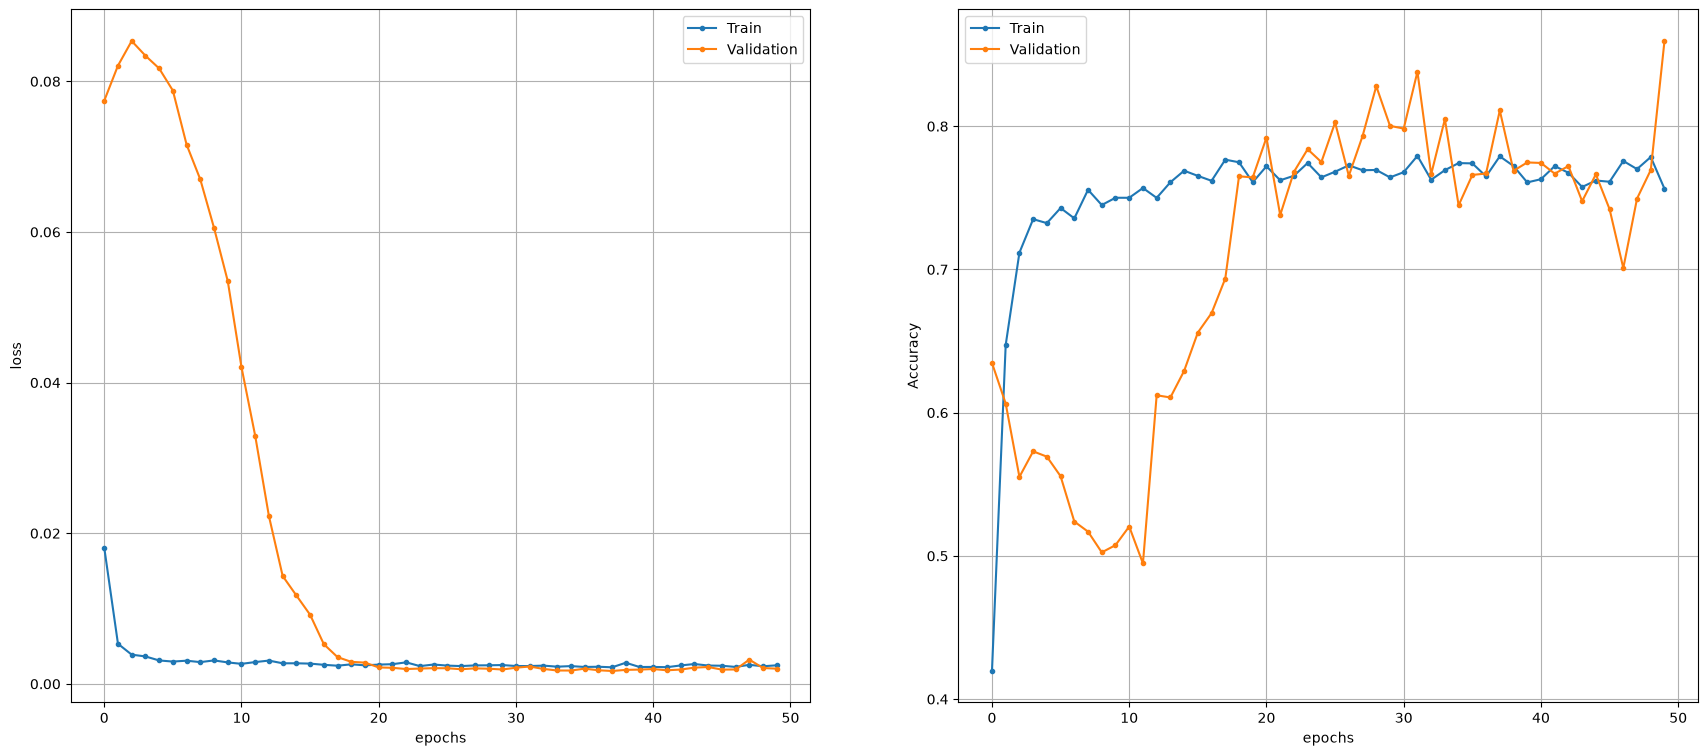

In [4]:
def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                               epochs, h['val_accuracy'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])

    print('Train Acc     ', h['accuracy'][-1])
    print('Validation Acc', h['val_accuracy'][-1])

plot_history(history)

(<Axes: title={'center': 'Result'}>,
 Text(0.5, 1.0, 'Result'))

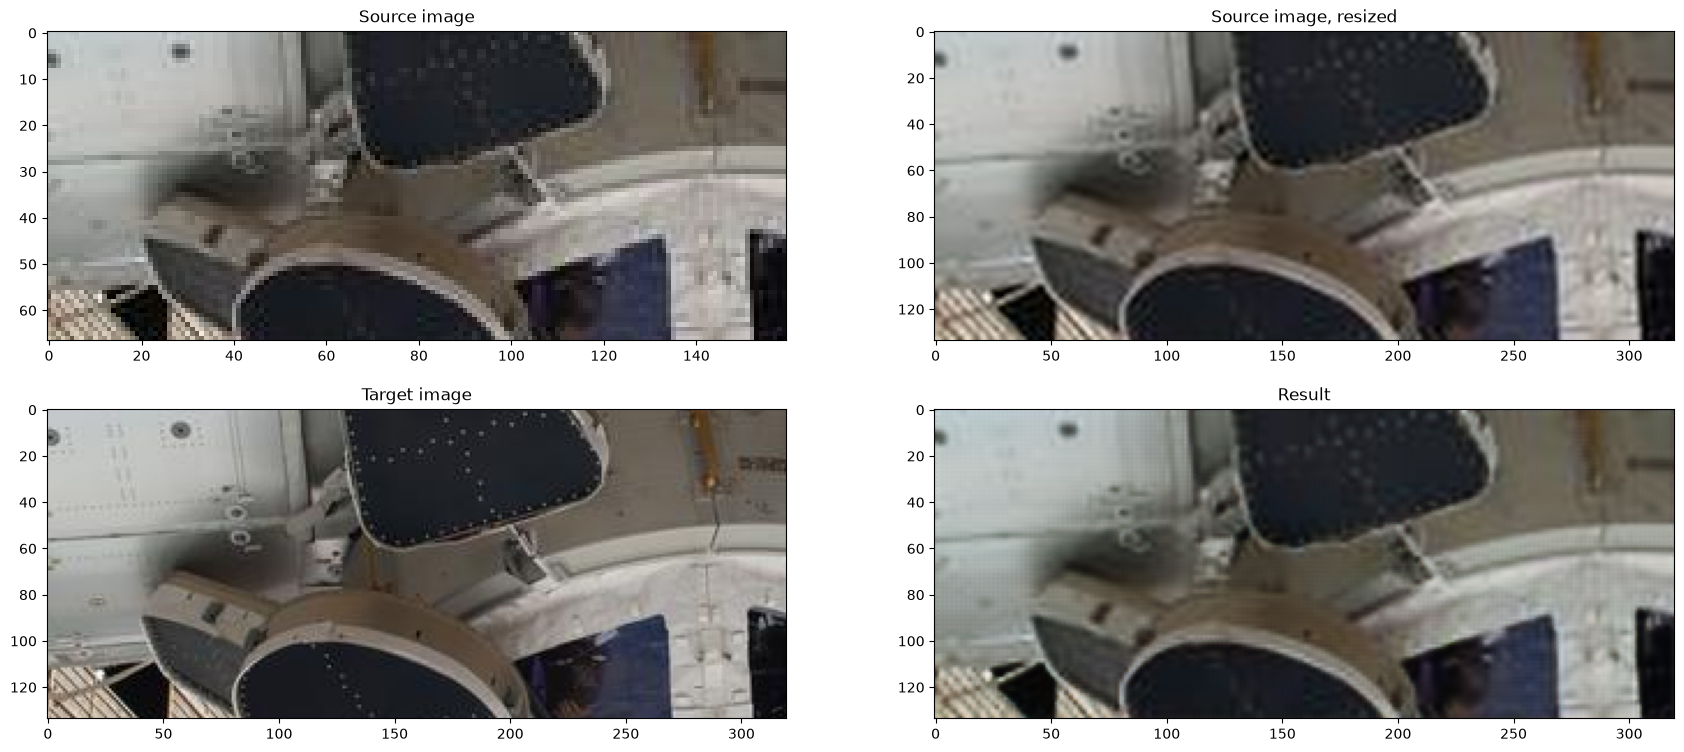

In [5]:
# visualize some results of the model
best_model = keras.models.load_model('best_model.keras')
v = ds.validation()
x, y = next(v)
res = best_model(x, training=False)
res = res[0].cpu().detach().numpy()

plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(x[0], cv2.COLOR_BGR2RGB)), plt.title('Source image')
plt.subplot(2, 2, 2), plt.imshow(cv2.cvtColor(np.clip(cv2.resize(x[0], None, fx=2, fy=2, interpolation=cv2.INTER_LANCZOS4), 0, 1), cv2.COLOR_BGR2RGB)), plt.title('Source image, resized')
plt.subplot(2, 2, 3), plt.imshow(cv2.cvtColor(y[0], cv2.COLOR_BGR2RGB)), plt.title('Target image')
plt.subplot(2, 2, 4), plt.imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB)), plt.title('Result')